# Contralesional Motor-Intent Decoding after Stroke
## Notebook 01 · Processing pipeline, step by step (single patient)

*Case study: EEG pipeline for an IpsiHand-type contralesional BCI · November 2026*

| | |
|---|---|
| **Purpose** | Rebuild from raw data the EEG processing chain of an IpsiHand-type BCI and justify every parameter |
| **Data** | Liu et al. 2024, acute stroke (NEMAR `nm000158`), patient 02 shown; group results in Notebook 02 |
| **Companion notebooks** | 02 group analysis (47 patients) · 03 replication on 3 more datasets · 04 advanced analyses |
| **Code** | all logic in the `kandu_eeg` package (`src/`); every function documents its rationale |

### Executive summary
- The raw recordings need **segment-aware processing**: the 8-s trial blocks are not contiguous, and the trigger channel contains glitches. Both are detected and handled (Section 3).
- The chain is **DC removal → 1 Hz high-pass → mains notch → 40 Hz low-pass → QC → 250 Hz → EOG regression → re-reference → epochs**. Each step is shown with its effect on the signal (Sections 2–9).
- Patient 02 shows a **β-band ERD (13–28 Hz) over the healthy hemisphere** during affected-hand imagery (Section 10).
- The choice of reference changes the apparent μ response (Section 9). The causal online controller is simulated in Section 13.

### Contents
0 Setup · 1 Clinical context · 2 Raw signal · 3 Events and data integrity · 4 Spectrum · 5 Filtering · 6 Downsampling · 7 Quality control · 8 Ocular artefacts · 9 Re-referencing · 10 ERD/ERS · 11 Features · 12 Decoding · 13 Pseudo-online simulation · 14 Pipeline summary

---

### Background
**The pipeline:**

> raw EEG → DC removal → high-pass → notch → low-pass → QC → downsample → EOG regression → re-reference → epochs → ERD/ERS → features → decoder → causal (online) controller

**How the device works (what we are emulating).**
After a stroke in one hemisphere, the hand on the *opposite* side is paretic. The motor cortex that normally drives that hand is damaged. IpsiHand records instead from the **healthy (contralesional) hemisphere**, which sits on the *same* side as the paretic hand. That hemisphere still produces a detectable *ipsilateral* motor-intent signal. When the patient tries to open or close the hand, μ/β power over that hemisphere drops (this drop is called ERD). The software detects the drop and drives a powered orthosis that opens the hand. The aim is Hebbian plasticity: *neurons that fire together, wire together*.

The published IpsiHand study (Bundy et al., *Stroke* 2017) used: 8 electrodes (F3 F4 T7 C3 Cz C4 T8 Pz), a **common-average reference**, **one control channel** (C3 or C4 over the healthy hemisphere), and **one patient-specific frequency** (9–19 Hz), estimated with an autoregressive (maximum-entropy) spectrum on **500 ms windows updated every 125 ms**. We model the Kandu configuration as **6 electrodes over the healthy hemisphere: 5 provide the noise reference, 1 is the control channel**.

**Dataset.** Liu et al., *Scientific Data* 2024 — *An EEG motor-imagery dataset for BCI in acute stroke patients* (NEMAR `nm000158`, figshare `10.6084/m9.figshare.21679035`).
50 acute stroke patients (1–30 days post-stroke), 29 EEG + 2 EOG channels at 500 Hz, wireless semi-dry ZhenTec NT1 headset, reference CPz, 40 trials of imagined hand-grip (20 left, 20 right). The clinical table includes the **paralysis side**, lesion location, NIHSS, MBI and mRS. That lets us define the contralesional hemisphere for each patient. It is the closest open match to the Kandu use case found: stroke patients, hand grasp, a clinical portable headset, and known lesion side.

| Kandu / IpsiHand | This dataset |
|---|---|
| chronic stroke, attempted movement | **acute** stroke, **imagined** movement |
| ~6 dry electrodes, one hemisphere | 29 semi-dry electrodes, whole head (we can *simulate* any subset) |
| rest vs move trials | 2 s instruction · 4 s MI · 2 s break per trial |
| 60 Hz mains (US) | 50 Hz mains (China) |

## 0 · Setup
All processing logic is implemented in the `kandu_eeg` package (`src/`); the notebook calls those functions. Each function's docstring states the method and the reason for each parameter.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from scipy import signal

from kandu_eeg import config as C, io, preprocessing as P, spatial as S, features as F, decoding as D, online as O, viz as V
mne.set_log_level("ERROR"); V.set_style()
print("MNE", mne.__version__, "| numpy", np.__version__)

SUBJECT = 2          # any usable patient 1..50 (recordings 5, 15 and 49 fail QC)

MNE 1.13.2 | numpy 2.5.3


## 1 · Clinical table → which hemisphere do we record from?
- **ParalysisSide** = the affected hand.
- **Contralesional hemisphere** = the healthy one = the *same side* as the affected hand (the motor pathways cross). This is where a Kandu headset sits.
- We derive it from the paralysis side, not the lesion text: most lesions here are **subcortical** (pons, basal ganglia, paraventricular), where "side" is ambiguous, and the clinic defines the device side by the paretic hand anyway.
- `side_concordant` flags patients whose lesion text does not sit opposite the paralysis (e.g., brainstem or cerebellar lesions), worth knowing when results look odd.

In [2]:
part = io.load_participants()
print(part[["affected_hand", "contralesional_hemi", "side_concordant", "cortical_lesion"]].apply(lambda c: c.value_counts().to_dict()))
part.loc[[SUBJECT], ["Gender", "Age", "Duration", "ParalysisSide", "StrokeLocation", "NIHSS", "MBI", "mRS", "contralesional_hemi"]]

affected_hand          {'left': 28, 'right': 22}
contralesional_hemi    {'left': 28, 'right': 22}
side_concordant             {True: 43, False: 7}
cortical_lesion            {False: 40, True: 10}
dtype: object


,Gender,Age,Duration,ParalysisSide,StrokeLocation,NIHSS,MBI,mRS,contralesional_hemi
subject,,,,,,,,,
2,male,60,2,left,Right pons,3,55,4,left


In [3]:
hemi = part.loc[SUBJECT, "contralesional_hemi"]
AFF  = part.loc[SUBJECT, "affected_hand"] + "_hand"
UNAFF = ("right" if AFF.startswith("left") else "left") + "_hand"
CTRL = S.resolve("CL:C", hemi)       # control electrode over the healthy hemisphere
IPSI = S.resolve("IL:C", hemi)       # homologous electrode over the lesioned hemisphere
KANDU6 = S.montage_channels("kandu6", hemi)
print(f"affected hand = {AFF}; record from the {hemi} hemisphere; control channel = {CTRL}; lesioned-side homologue = {IPSI}")
print("Kandu-like 6-electrode montage:", KANDU6)

affected hand = left_hand; record from the left hemisphere; control channel = C3; lesioned-side homologue = C4
Kandu-like 6-electrode montage: ['F3', 'FC3', 'C3', 'CP3', 'P3', 'Cz']


## 2 · Raw data: what does the amplifier actually give us?
`io.load_raw` builds an MNE `Raw` object. Units: µV → **V** (MNE always uses SI). Nothing is filtered yet.

Look at the **channel means**. They are in the *millivolt* range: the amplifier is **DC-coupled**, so each electrode carries a large, slowly drifting electrode–skin offset (a half-cell potential, plus sweat). EEG itself is ~10–50 µV. That's why step 1 is DC removal: a filter started on a 10 mV offset produces a transient 1000× larger than the EEG.

In [4]:
raw0 = io.load_raw(SUBJECT)
print(raw0)
X0 = raw0.get_data(picks="eeg")
df = pd.DataFrame({"mean (mV)": X0.mean(1) * 1e3, "std (µV)": X0.std(1) * 1e6}, index=raw0.copy().pick("eeg").ch_names)
df.T.round(1)

<RawArray | 31 x 160000 (320.0 s), ~37.9 MiB, data loaded>


,Fp1,Fp2,Fz,F3,F4,F7,F8,FCz,FC3,FC4,...,TP7,TP8,Pz,P3,P4,P7,P8,Oz,O1,O2
mean (mV),0.8,6.7,-2.7,21.4,14.2,20.9,10.6,3.9,13.8,13.6,...,21.0,18.4,16.8,21.1,18.9,22.1,23.7,20.3,20.1,19.0
std (µV),176.8,430.4,142.0,252.0,128.1,160.7,515.3,249.2,163.7,204.9,...,135.1,387.6,137.0,185.8,325.2,166.0,575.2,193.3,172.2,290.4


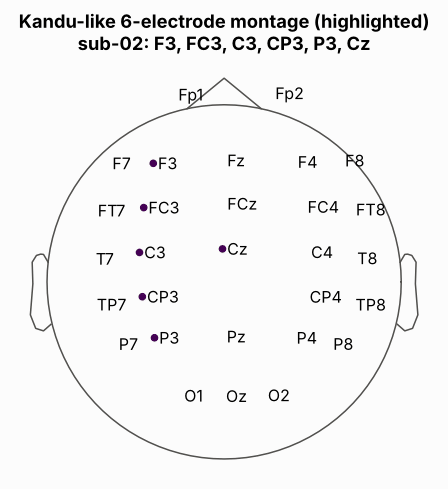

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
eeg_info = raw0.copy().pick("eeg").info
mne.viz.plot_sensors(eeg_info, show_names=True, axes=ax, show=False,
                     ch_groups=[[eeg_info.ch_names.index(c) for c in KANDU6]], linewidth=0)
ax.set_title(f"Kandu-like 6-electrode montage (highlighted)\nsub-{SUBJECT:02d}: {', '.join(KANDU6)}"); plt.show()

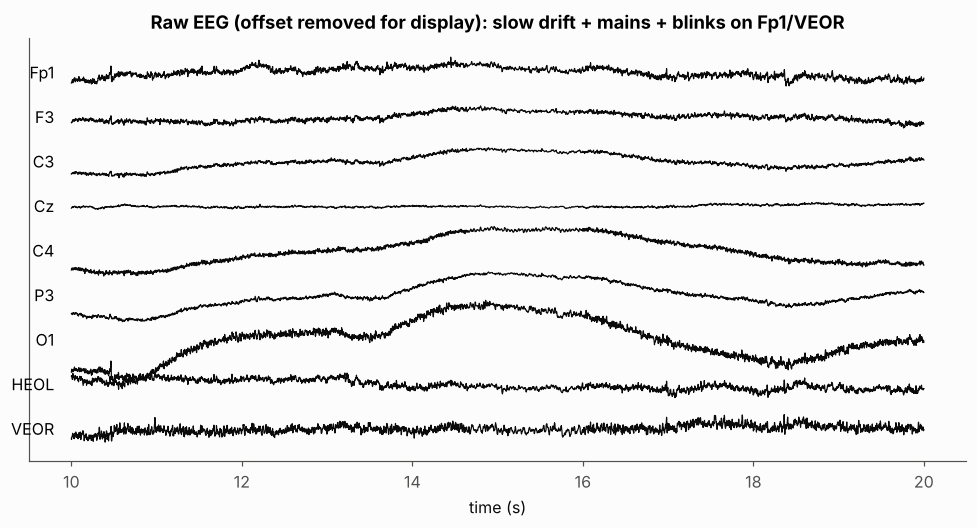

In [6]:
# 10 s of raw data (per-channel mean removed ONLY for display)
seg = raw0.copy().crop(10, 20).pick(["Fp1", "F3", "C3", "Cz", "C4", "P3", "O1", "HEOL", "VEOR"])
d = seg.get_data(); d = d - d.mean(1, keepdims=True)
fig, ax = plt.subplots(figsize=(11, 5))
for i, (ch, x) in enumerate(zip(seg.ch_names, d)):
    ax.plot(seg.times + 10, x * 1e6 - i * 150, lw=0.8, color=V.INK)
    ax.text(9.8, -i * 150, ch, ha="right", va="center")
ax.set_yticks([]); ax.set_xlabel("time (s)"); ax.set_title("Raw EEG (offset removed for display): slow drift + mains + blinks on Fp1/VEOR")
ax.grid(False); plt.show()

## 3 · Events and trial structure (and two data traps)
Each trial lasts 8 s: **instruction** (2 s, cue picture of the left or right hand) → **motor imagery** (4 s, a video of a hand gripping a ball plays) → **break** (2 s).
The trigger channel holds 1-sample pulses (1 = instruction, 2 = MI onset, 3 = break). Everything is time-locked to **MI onset = t 0**.

**Trap 1: dirty triggers.** Some trigger samples have non-integer values (2.79, 0.12, …). These are glitches, so we keep only *exact* codes. In 11 patients, one trial has its MI marker at the very first sample of the block. It has no pre-cue data, so we flag it `BAD_no_baseline` and drop it.

**Trap 2: the 8-s blocks are not truly contiguous.** The file stores `(40 trials, 33 channels, 4000 samples)`. If you concatenate the blocks and filter, you get artefacts at every join, because the signal jumps between blocks (measured below). The fix is to filter each block as its own **segment** (MNE `EDGE boundary` annotations), with reflection padding.

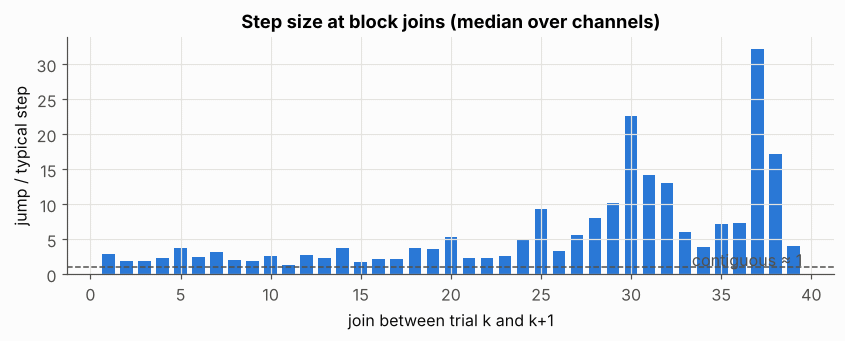

<Annotations | 8 segments: EDGE boundary (2), break/left_hand (1), ...>


In [7]:
Xm, labels = io.load_mat(SUBJECT)
E = np.delete(Xm[:, :31, :], 17, axis=1)        # drop row 18 = CPz (the reference: a flat constant, step size 0)
typ = np.median(np.abs(np.diff(E, axis=2)), axis=(0, 2))
jump = np.median(np.abs(E[1:, :, 0] - E[:-1, :, -1]) / typ[None], axis=1)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(np.arange(1, 40), jump, color=V.SERIES[0], width=0.7)
ax.axhline(1, color=V.INK2, ls="--", lw=1); ax.text(39.5, 1.2, "contiguous ≈ 1", ha="right", color=V.INK2)
ax.set_xlabel("join between trial k and k+1"); ax.set_ylabel("jump / typical step"); ax.set_title("Step size at block joins (median over channels)")
plt.show()
print(raw0.annotations[:8])

## 4 · Power spectrum of the raw signal: what is in there?
**PSD** (power spectral density, V²/Hz, shown in dB = 10·log10) via **Welch's method**: cut the signal into overlapping windows (2 s, Hann taper, 50% overlap), FFT each, average the |FFT|². Averaging reduces variance. Frequency resolution = fs / nperseg = 500/1000 = **0.5 Hz**.

What to look for:
- **1/f shape** (the aperiodic background). Real EEG power falls with frequency.
- **μ peak 8–13 Hz** over sensorimotor cortex. The **β band 13–30 Hz** often shows a smaller hump.
- **Mains at 50 Hz** and its harmonics 100/150/200 Hz. They are line-shaped because the mains frequency is very stable.
- **< 1 Hz** drift, and **> 40 Hz** mostly muscle (EMG).
- **Nyquist** = fs/2 = 250 Hz: the highest frequency a 500 Hz recording can represent.

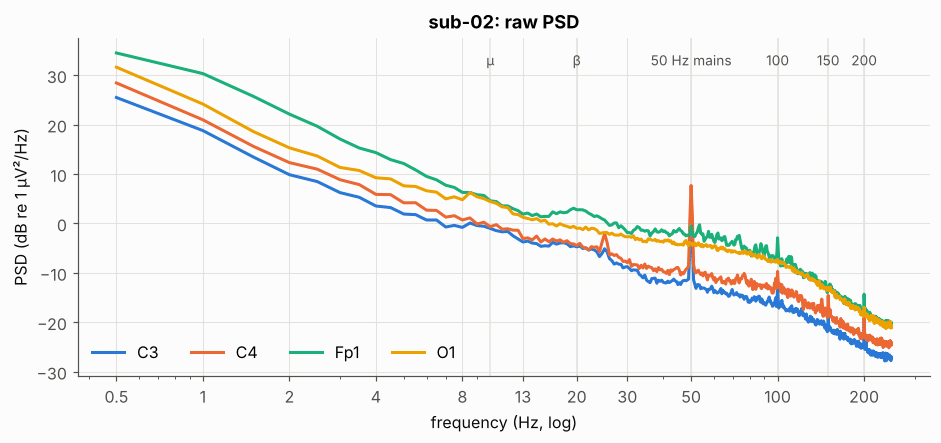

In [8]:
r = P.remove_dc(raw0)
psd = r.compute_psd(method="welch", fmin=0.2, fmax=249, n_fft=1000, n_overlap=500, picks=[CTRL, IPSI, "Fp1", "O1"])
fig, ax = plt.subplots(figsize=(10, 4))
for i, ch in enumerate(psd.ch_names):
    ax.semilogx(psd.freqs, 10 * np.log10(psd.get_data()[i] * 1e12), label=ch, color=V.SERIES[i])
for f0, txt in [(10, "μ"), (20, "β"), (50, "50 Hz mains"), (100, "100"), (150, "150"), (200, "200")]:
    ax.axvline(f0, color=V.GRID, lw=1, zorder=0); ax.text(f0, 32, txt, ha="center", color=V.INK2, fontsize=9)
ax.set_xlabel("frequency (Hz, log)"); ax.set_ylabel("PSD (dB re 1 µV²/Hz)"); ax.legend(ncol=4); ax.set_title(f"sub-{SUBJECT:02d}: raw PSD")
ax.set_xticks([0.5, 1, 2, 4, 8, 13, 20, 30, 50, 100, 200]); ax.set_xticklabels([0.5, 1, 2, 4, 8, 13, 20, 30, 50, 100, 200]); plt.show()

**Observation (patient 02).** A clean 1/f background. The 50 Hz line rises ~10 dB above its neighbours on C4, with smaller harmonics. Fp1 (frontal) has the most low-frequency power (eyes) and the most > 30 Hz power (forehead muscles). There is no strong μ peak: it is common for μ to be weak in older, acute stroke patients, which is one reason the decoder searches across μ *and* β.

## 5 · Filtering, one step at a time

### 5.1 Terminology
| Term | Meaning |
|---|---|
| **Pass-band / stop-band** | frequencies kept / removed |
| **Cut-off (−6 dB for MNE FIR, −3 dB for Butterworth)** | the edge frequency you specify |
| **Transition bandwidth** | width of the ramp between pass and stop. Narrower ramp → longer filter → more delay and ringing |
| **Order / length** | number of coefficients (FIR) or poles (IIR); sets how steep the filter is |
| **FIR** (finite impulse response) | output = weighted sum of past inputs. Always stable, can be exactly **linear-phase** (all frequencies delayed equally, so no waveform distortion). Needs many taps for sharp, low cut-offs |
| **IIR** (infinite impulse response, e.g. Butterworth) | uses past *outputs* too (feedback). Very cheap and steep, but **non-linear phase**, and can be unstable if badly designed |
| **Zero-phase** | apply the filter forward *and* backward (`filtfilt`), or compensate an FIR's delay. No delay at all, but it needs future samples → **offline only** |
| **Causal** | uses only past samples → the only option on a device. Introduces a delay (group delay) |
| **Group delay** | how long each frequency is delayed (s). For a linear-phase FIR it is constant = (N−1)/2 samples |
| **Ringing / edge effects** | oscillatory artefacts after sharp transients or at data edges |
| **Notch** | very narrow band-stop for one frequency (mains) |

### 5.2 High-pass at 1 Hz: why 1 Hz?
- It removes drift, sweat and electrode-movement artefacts (< 1 Hz), which are huge in a wireless, semi-dry, bedside recording.
- We study **oscillations** (μ/β), not slow potentials. If we analysed movement-related cortical potentials (MRCP, ~0.1–1 Hz, also used in stroke BCIs), we would need 0.05–0.1 Hz instead.
- A high-pass also makes the data zero-mean, which CAR, ICA and covariance-based methods (CSP, Riemann) assume.

Below: the actual filter MNE designs (FIR, Hamming window, `firwin`). Note the **length** it chooses. MNE's rule is transition band = min(max(0.25·f, 2 Hz), f), so 1 Hz here, and length ≈ 3.3 / transition = **3.3 s = 1651 taps** at 500 Hz. A low cut-off needs a long FIR.

high-pass 1 Hz FIR: 1651 taps = 3.30 s; delay compensated -> zero phase
band-pass 1-40 Hz FIR: 1651 taps


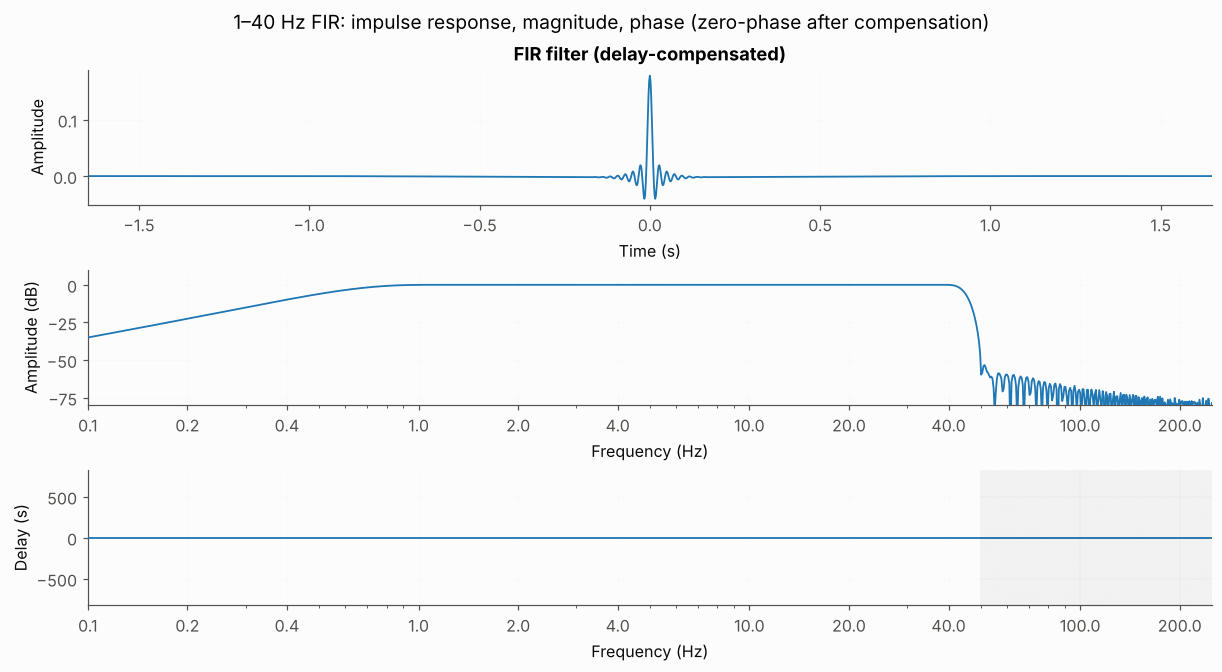

In [9]:
sf = raw0.info["sfreq"]
h_hp = mne.filter.create_filter(None, sf, l_freq=C.HIGHPASS, h_freq=None, method="fir", fir_design="firwin", fir_window="hamming")
h_bp = mne.filter.create_filter(None, sf, l_freq=C.HIGHPASS, h_freq=C.LOWPASS, method="fir", fir_design="firwin", fir_window="hamming")
print(f"high-pass 1 Hz FIR: {len(h_hp)} taps = {len(h_hp)/sf:.2f} s; delay compensated -> zero phase")
print(f"band-pass 1-40 Hz FIR: {len(h_bp)} taps")
fig = mne.viz.plot_filter(h_bp, sf, freq=None, gain=None, flim=(0.1, 250), fscale="log", show=False, compensate=True)
fig.set_size_inches(11, 6); fig.suptitle("1–40 Hz FIR: impulse response, magnitude, phase (zero-phase after compensation)"); plt.show()

How to read it: **top**, the impulse response (symmetric, so linear-phase, and ±0.15 s of ringing around the centre); **middle**, the magnitude response (the −6 dB points at 1 and 40 Hz, > 50 dB of attenuation above ~45 Hz: the Hamming window's typical stop-band); **bottom**, delay = 0 once compensated, i.e. zero-phase.

### 5.3 Notch at 50 Hz (and harmonics): do we need it?
If the low-pass is at 40 Hz, the 50 Hz line is already attenuated by the low-pass stop-band (≥ 50 dB with a Hamming FIR). The notch matters when:
1. you keep content above 50 Hz (gamma, or **EMG detection** to catch patients who actually move or clench),
2. the mains is so strong that it leaks through the transition band,
3. you use a short or causal IIR low-pass with a shallow roll-off.

Kandu (US) would notch **60 Hz** and 120/180 Hz. We still apply it, and keep the cost in mind: a notch removes a little real EEG near 50 Hz, and a sharp IIR notch rings.

The line-noise level is also a **quality metric**. More mains pickup on a channel means higher electrode impedance, i.e. poor contact.

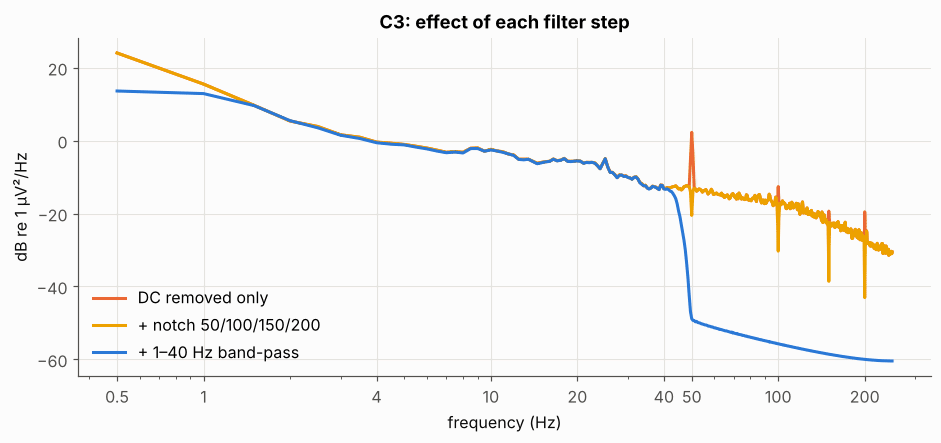

                  C4  CP4  FC4   C3   F3  CP3
mains SNR (dB)  13.5  8.8  8.3  7.6  5.9  5.7


In [10]:
r_notch = r.copy().notch_filter(C.NOTCH_FREQS, picks=["eeg", "eog"])
r_filt = P.filter_offline(r)
fig, ax = plt.subplots(figsize=(10, 4))
for lab, rr, col in [("DC removed only", r, V.SERIES[1]), ("+ notch 50/100/150/200", r_notch, V.SERIES[3]), ("+ 1–40 Hz band-pass", r_filt, V.SERIES[0])]:
    p = rr.compute_psd(fmin=0.2, fmax=249, n_fft=1000, picks=[CTRL])
    ax.semilogx(p.freqs, 10 * np.log10(p.get_data()[0] * 1e12), label=lab, color=col)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("dB re 1 µV²/Hz"); ax.legend(); ax.set_title(f"{CTRL}: effect of each filter step")
ax.set_xticks([0.5, 1, 4, 10, 20, 40, 50, 100, 200]); ax.set_xticklabels([0.5, 1, 4, 10, 20, 40, 50, 100, 200]); plt.show()
print(P.line_noise_ratio(raw0).sort_values(ascending=False).round(1).head(6).to_frame("mains SNR (dB)").T)

### 5.4 Zero-phase (offline) vs causal (device): the latency question
A device cannot use future samples, so it uses a **causal IIR**, e.g. a 4th-order Butterworth band-pass 8–30 Hz with `sosfilt` and a carried state. The price is **group delay**: the filtered signal lags the true one, by tens of ms in the μ band. For a closed-loop rehab device this adds directly to the brain→orthosis latency, which should stay well under ~1 s for Hebbian pairing to work.

`sos` = second-order sections: the numerically stable way to run IIR filters (never use the `b, a` form for high orders or low cut-offs).

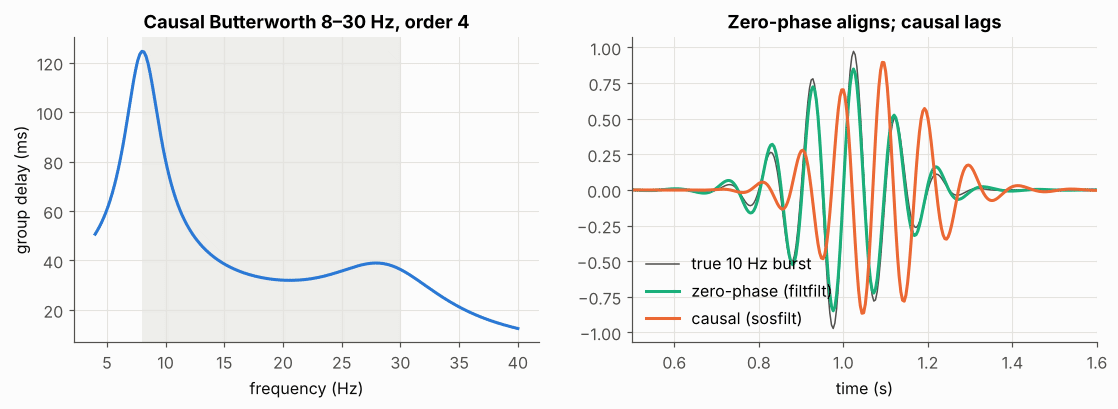

group delay at 10 Hz: 80 ms, at 20 Hz: 32 ms


In [11]:
bp = P.CausalBandpass(sfreq=250, l_freq=8, h_freq=30, order=4)
fq = np.linspace(4, 40, 200)
gd = bp.group_delay(fq) * 1000
t = np.arange(0, 2, 1/250); burst = np.sin(2*np.pi*10*t) * np.exp(-((t-1)/0.15)**2)
y_causal = signal.sosfilt(bp.sos, burst); y_zero = signal.sosfiltfilt(bp.sos, burst)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(fq, gd, color=V.SERIES[0]); ax[0].axvspan(8, 30, color=V.GRID, alpha=.6, lw=0)
ax[0].set_xlabel("frequency (Hz)"); ax[0].set_ylabel("group delay (ms)"); ax[0].set_title("Causal Butterworth 8–30 Hz, order 4")
ax[1].plot(t, burst, color=V.INK2, lw=1, label="true 10 Hz burst")
ax[1].plot(t, y_zero, color=V.SERIES[2], label="zero-phase (filtfilt)")
ax[1].plot(t, y_causal, color=V.SERIES[1], label="causal (sosfilt)")
ax[1].set_xlim(0.5, 1.6); ax[1].legend(loc="lower left"); ax[1].set_xlabel("time (s)"); ax[1].set_title("Zero-phase aligns; causal lags")
plt.show()
print(f"group delay at 10 Hz: {np.interp(10, fq, gd):.0f} ms, at 20 Hz: {np.interp(20, fq, gd):.0f} ms")

### 5.5 Edge effects: why we filter per segment
Below: one channel, two adjacent blocks. Filtering *across* the join smears the step into a long transient (the filter's step response). Filtering each segment separately (MNE does this automatically with `EDGE` annotations, and pads by reflection) avoids it.

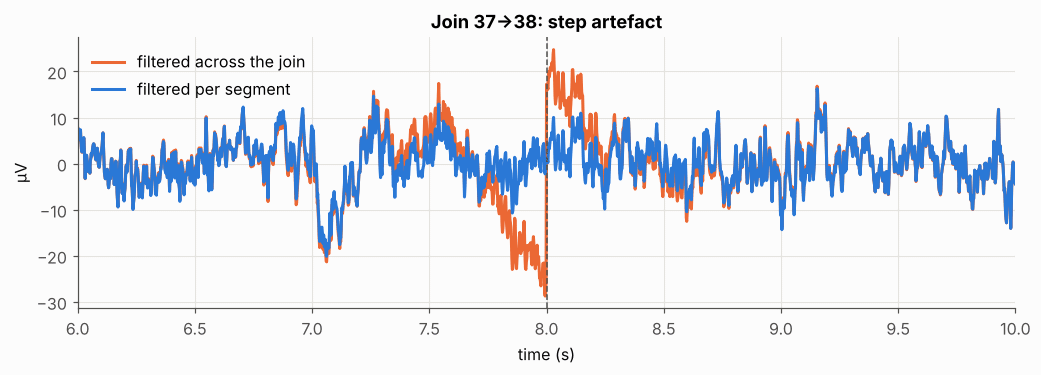

In [12]:
k = int(np.argmax(jump)); ch = 13  # C3 (row 14 of the .mat; rows before CPz keep their index)
x = np.r_[E[k, ch], E[k + 1, ch]] * 1e-6; x = x - x.mean()
sos_hp = signal.butter(4, 1, "highpass", fs=500, output="sos")
across = signal.sosfiltfilt(sos_hp, x)
per_seg = np.r_[signal.sosfiltfilt(sos_hp, x[:4000] - x[:4000].mean()), signal.sosfiltfilt(sos_hp, x[4000:] - x[4000:].mean())]
tt = np.arange(len(x)) / 500
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(tt, across * 1e6, color=V.SERIES[1], label="filtered across the join")
ax.plot(tt, per_seg * 1e6, color=V.SERIES[0], label="filtered per segment")
ax.axvline(8, color=V.INK2, ls="--", lw=1); ax.set_xlim(6, 10); ax.set_xlabel("time (s)"); ax.set_ylabel("µV"); ax.legend(); ax.set_title(f"Join {k+1}→{k+2}: step artefact")
plt.show()

## 6 · Downsampling 500 → 250 Hz (and the aliasing trap)
**Nyquist theorem:** a signal sampled at fs only represents frequencies below **fs/2**. Anything above fs/2 that is still in the data when you drop samples **folds back** (aliases) to `|f − k·fs|`.

Why downsample at all? Our band of interest is < 40 Hz, so 250 Hz (Nyquist 125 Hz) loses nothing. It halves memory and CPU (important on a tablet or embedded board) and makes AR models better conditioned. Even **125 Hz** works for μ/β (tested in notebook 02).

**Rule: low-pass first (anti-aliasing), then decimate.** `mne.resample` / `scipy.signal.resample_poly` do both. Demo: decimate the *unfiltered* signal naively by 4 (to 125 Hz). The 100 Hz and 150 Hz mains harmonics alias to |100 − 125| = **25 Hz** and |150 − 125| = **25 Hz**, landing right in the **β band** where they would look like brain signal.

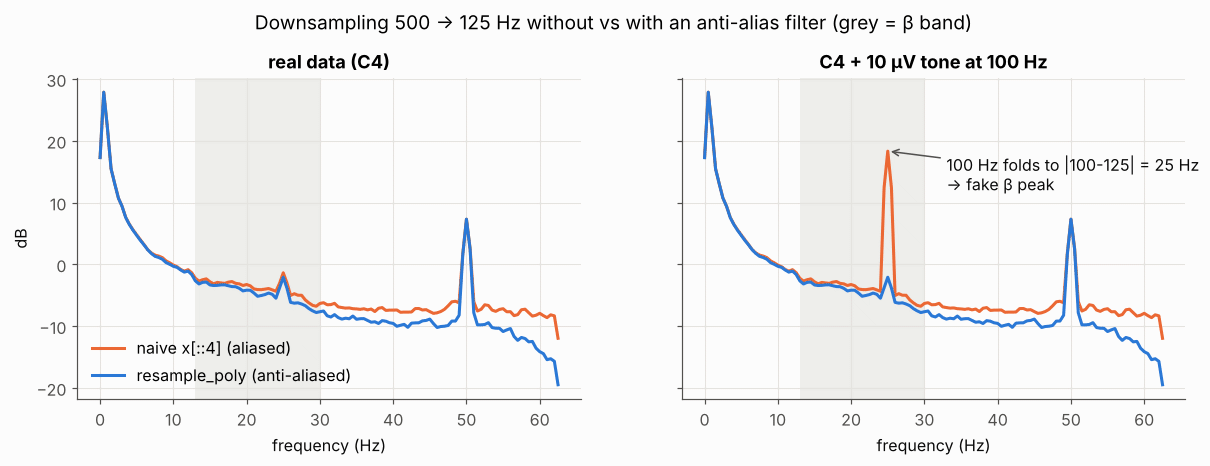

In [13]:
worst = P.line_noise_ratio(raw0).idxmax()                 # channel with the most mains pickup
x = r.copy().pick([worst]).get_data()[0]
t = np.arange(len(x)) / 500
x_syn = x + 10e-6 * np.sin(2 * np.pi * 100 * t)            # + a 10 µV, 100 Hz tone (a mains harmonic)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, sig, ttl in [(axs[0], x, f"real data ({worst})"), (axs[1], x_syn, f"{worst} + 10 µV tone at 100 Hz")]:
    naive = sig[::4]                                       # WRONG: no anti-alias filter
    proper = signal.resample_poly(sig, 1, 4)               # low-pass FIR + decimate
    f1, p1 = signal.welch(naive, fs=125, nperseg=250); f2, p2 = signal.welch(proper, fs=125, nperseg=250)
    a.plot(f1, 10*np.log10(p1*1e12), color=V.SERIES[1], label="naive x[::4] (aliased)")
    a.plot(f2, 10*np.log10(p2*1e12), color=V.SERIES[0], label="resample_poly (anti-aliased)")
    a.axvspan(13, 30, color=V.GRID, alpha=.6, lw=0); a.set_xlabel("frequency (Hz)"); a.set_title(ttl)
axs[1].annotate("100 Hz folds to |100-125| = 25 Hz\n-> fake β peak", xy=(25, 10*np.log10(signal.welch(x_syn[::4], fs=125, nperseg=250)[1][50]*1e12)),
                xytext=(33, 12), arrowprops=dict(arrowstyle="->", color=V.INK2), color=V.INK)
axs[0].set_ylabel("dB"); axs[0].legend(loc="lower left"); fig.suptitle("Downsampling 500 -> 125 Hz without vs with an anti-alias filter (grey = β band)", y=1.04); plt.show()

## 7 · Quality control: channel level, then recording level
On the **filtered** data (otherwise drift makes every channel look bad):
- `std_uv` with a **robust z-score** (median / MAD rather than mean / SD, so one terrible channel doesn't hide the others) → *noisy*.
- `corr_neighbours`: a real channel correlates with its neighbours (volume conduction). ~0 → *dead / loose*; ~1 → *bridged* (gel or saline smear). The threshold is lenient because Cz and Pz sit next to the CPz reference: they measure a small difference and are naturally less correlated.
- **Recording level: the aperiodic (1/f) slope.** log-PSD vs log-f has slope −1 to −2 in real EEG. A slope ≈ 0 is **white noise**: the amplifier or reference failed. Three patients (5, 15, 49) fail this test and are excluded entirely. That is the kind of automatic check a home-use device needs.

Bad channels are then **interpolated** with spherical splines (from their neighbours' positions). On a 6-electrode headset interpolation is not possible, so the session should be **flagged** instead.

aperiodic slope: -1.17


,Fp1,Fp2,Fz,F3,F4,F7,F8,FCz,FC3,FC4,...,TP7,TP8,Pz,P3,P4,P7,P8,Oz,O1,O2
std_uv,29.52,52.46,9.7,9.57,11.97,12.5,22.3,7.0,8.69,7.77,...,10.77,8.62,4.76,8.06,6.61,10.48,9.02,10.63,11.22,9.64
robust_z,7.18,15.45,0.02,-0.02,0.84,1.03,4.57,-0.95,-0.34,-0.67,...,0.41,-0.37,-1.76,-0.57,-1.09,0.3,-0.22,0.36,0.57,0.0
corr_neighbours,0.75,0.47,0.81,0.78,0.81,0.78,0.51,0.62,0.73,0.81,...,0.91,0.87,0.53,0.67,0.85,0.83,0.77,0.82,0.79,0.79
flat,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
noisy,True,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
uncorrelated,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
bad,True,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


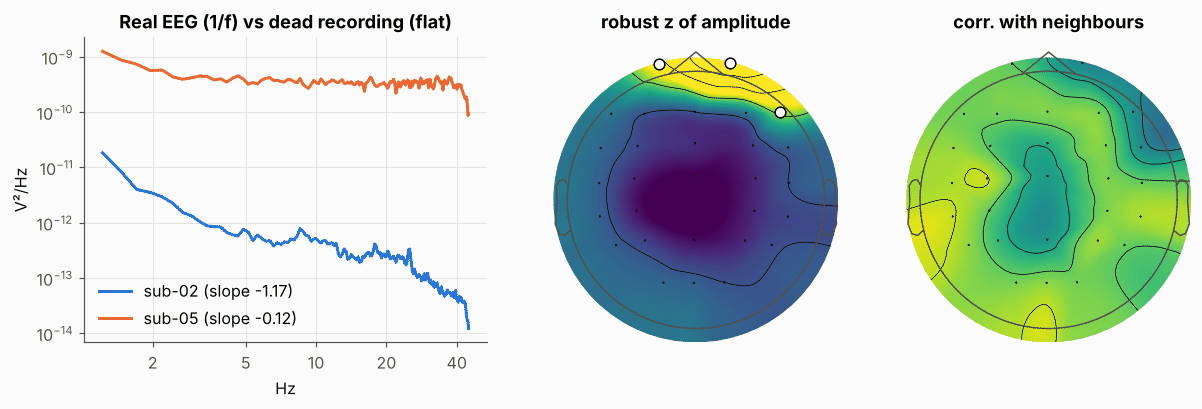

In [14]:
qc = P.channel_qc(r_filt)
print("aperiodic slope:", round(P.aperiodic_slope(r_filt), 2))
display(qc.round(2).T)
dead = P.filter_offline(P.remove_dc(io.load_raw(5)))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
for rr, lab, col in [(r_filt, f"sub-{SUBJECT:02d} (slope {P.aperiodic_slope(r_filt):.2f})", V.SERIES[0]), (dead, f"sub-05 (slope {P.aperiodic_slope(dead):.2f})", V.SERIES[1])]:
    p = rr.compute_psd(fmin=1, fmax=45, picks=["C3"]); ax[0].loglog(p.freqs, p.get_data()[0], label=lab, color=col)
ax[0].set_xticks([2, 5, 10, 20, 40]); ax[0].set_xticklabels([2, 5, 10, 20, 40]); ax[0].minorticks_off()
ax[0].set_xlabel("Hz"); ax[0].set_ylabel("V²/Hz"); ax[0].legend(); ax[0].set_title("Real EEG (1/f) vs dead recording (flat)")
V.topomap(qc["robust_z"].to_dict(), ax[1], cmap="viridis", vlim=(-2, 6), title="robust z of amplitude", mask_chs=list(qc.index[qc.bad]))
V.topomap(qc["corr_neighbours"].to_dict(), ax[2], cmap="viridis", vlim=(0, 1), title="corr. with neighbours")
plt.show()

## 8 · Ocular artefacts: EOG regression
Blinks and eye movements produce large, low-frequency potentials, strongest at the front. We remove them by **linear regression** on the two EOG channels:

$$\text{EEG}_{clean} = \text{EEG} - B\,\text{EOG},\qquad B = \text{EEG}\,\text{EOG}^\top(\text{EOG}\,\text{EOG}^\top)^{-1}$$

Why not ICA? ICA works well with many channels (≥ ~20), but a 6-electrode headset cannot separate sources, and ICA needs offline fitting. Regression is deterministic, cheap and online-compatible. Its caveat: EOG electrodes also pick up some frontal EEG, so a little brain signal is removed too (negligible at C3/C4).

Then we **reject trials** by peak-to-peak amplitude > 150 µV, judged **only on the sensorimotor channels the decoder uses**, so a blink on Fp1 doesn't throw away a trial whose C3 is clean.

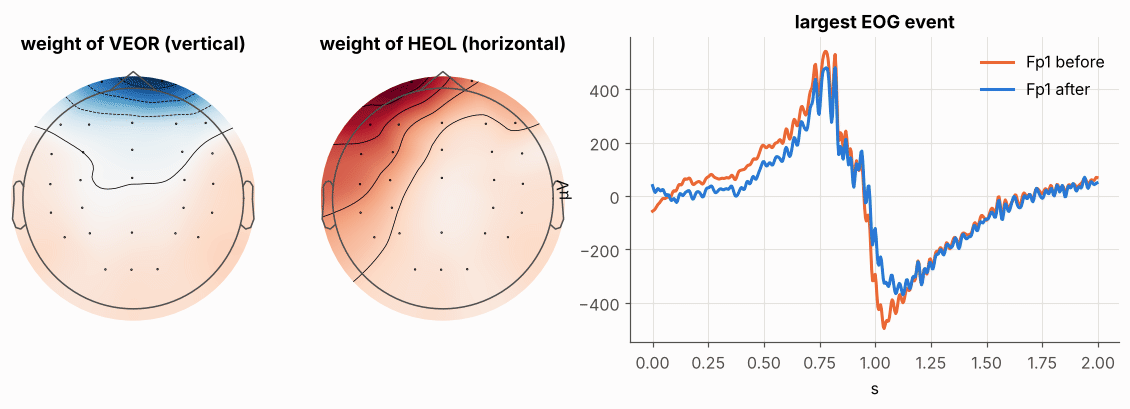

In [15]:
r_ds = P.downsample(r_filt)
r_eog, B = P.eog_regression(r_ds)
eeg_names = [c for c in r_ds.ch_names if c not in C.EOG_CHANNELS]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 2]))
V.topomap(dict(zip(eeg_names, B[:, 1])), ax[0], title="weight of VEOR (vertical)")
V.topomap(dict(zip(eeg_names, B[:, 0])), ax[1], title="weight of HEOL (horizontal)")
veor = r_ds.get_data(picks="VEOR")[0]; i0 = int(np.argmax(np.abs(veor))); sl = slice(max(0, i0-250), i0+250)
tt = np.arange(sl.stop - sl.start) / 250
ax[2].plot(tt, r_ds.get_data(picks="Fp1")[0][sl]*1e6, color=V.SERIES[1], label="Fp1 before")
ax[2].plot(tt, r_eog.get_data(picks="Fp1")[0][sl]*1e6, color=V.SERIES[0], label="Fp1 after")
ax[2].legend(); ax[2].set_xlabel("s"); ax[2].set_ylabel("µV"); ax[2].set_title("largest EOG event")
plt.show()

## 9 · Re-referencing: the "5 electrodes reduce the noise, 1 is used" idea
Every EEG channel is a **difference** between two electrodes. The question is what you subtract from the control electrode:

| Derivation | Formula | # electrodes | Effect |
|---|---|---|---|
| **as recorded** | C3 − CPz | 2 | CPz is ~2 cm from C3, so part of the motor signal is subtracted away |
| **bipolar** | C3 − CP3 | 2 | cheapest; cancels whatever the two sites share |
| **small Laplacian** | C3 − ¼(FC3 + CP3 + T7 + Cz) | 5 | a *spatial high-pass*: keeps focal activity, removes broad noise |
| **CAR-6 (Kandu-like)** | C3 − mean(6 montage electrodes) | 6 | removes what is common to all sensors (mains, movement, global drifts) |
| **CAR-29** | C3 − mean(all 29) | 29 | an approximation of reference-free potentials; better with dense, whole-head coverage |

With few electrodes clustered on one side, **CAR is not "reference-free"**: the average is itself dominated by the region you care about, and a strong ERD under C3 is partly subtracted from itself. Notebook 02 tests which derivation works best, i.e. how many electrodes are really needed.

<Epochs | 40 events (all good), -1.9 – 5 s (baseline off), ~16.4 MiB, data loaded,
 'left_hand': 20
 'right_hand': 20>
trials kept after 150 µV p-p on ['FC3', 'C3', 'CP3', 'FC4', 'C4', 'CP4', 'Cz']: 39/40


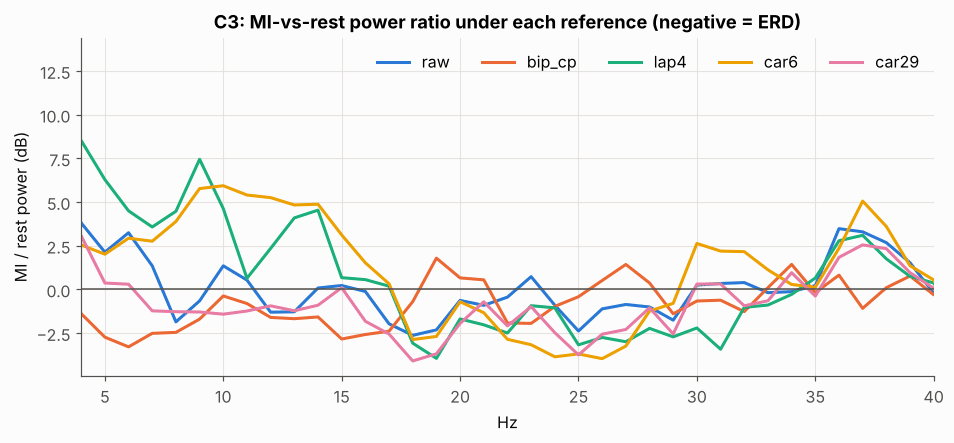

In [16]:
raw_clean, qc_full = P.preprocess(SUBJECT)
ep = P.make_epochs(raw_clean, reject_ptp=None)
roi = [S.resolve(x, hemi) for x in ["CL:FC", "CL:C", "CL:CP", "IL:FC", "IL:C", "IL:CP"]] + ["Cz"]
keep = P.reject_trials_ptp(ep, roi)
print(ep); print(f"trials kept after 150 µV p-p on {roi}: {keep.sum()}/{len(keep)}")
ds = D.build_intent_dataset(ep, SUBJECT, hemi, AFF, "affected", keep)
fig, ax = plt.subplots(figsize=(10, 4))
for i, der in enumerate(["raw", "bip_cp", "lap4", "car6", "car29"]):
    x = D.control_signal(ds, der)
    f, pr = signal.welch(x[ds.y == 0], fs=250, nperseg=250); f, pm = signal.welch(x[ds.y == 1], fs=250, nperseg=250)
    ax.plot(f, 10*np.log10(pm.mean(0)/pr.mean(0)), label=der, color=V.SERIES[i])
ax.axhline(0, color=V.INK2, lw=1); ax.set_xlim(4, 40); ax.set_xlabel("Hz"); ax.set_ylabel("MI / rest power (dB)")
ax.legend(ncol=5); ax.set_title(f"{CTRL}: MI-vs-rest power ratio under each reference (negative = ERD)"); plt.show()

**Observation.** For β (17–28 Hz) every derivation shows ERD at C3, but they disagree in μ. **CAR-6 and the Laplacian turn μ into an apparent *increase***, while C−CPz, C−CP and CAR-29 keep a μ decrease. A re-referenced channel is C3 *minus* its reference. If the reference electrodes (FC3, CP3, T7, Cz… all on the same, desynchronising hemisphere) lose *more* μ power than C3 does, the difference looks like a power gain. The r² map below confirms that the strongest ERD here is at CP3 rather than C3. This directly bears on "can we use fewer electrodes?": *which* electrodes go into the reference, and where the patient's ERD peaks, matter as much as *how many*.

## 10 · ERD/ERS: the physiological signal itself
**ERD** (event-related desynchronisation) is a *decrease* in μ/β power when the motor cortex gets engaged (preparation, execution, imagery): neurons stop oscillating in sync. **ERS** is an *increase*. The best-known example is the **post-movement β rebound** right after the movement or imagery ends.

**Pfurtscheller's method (1999)**, as implemented in `features.erd_timecourse`:
1. band-pass the epochs (μ 8–13 Hz or β 13–30 Hz, zero-phase),
2. square → instantaneous power,
3. subtract the *evoked* (phase-locked) power (inter-trial-variance method), so only the *induced* change remains,
4. average over trials,
5. smooth (250 ms moving average),
6. express as % of a **reference interval** R (here −1.5 to −0.5 s): ERD% = (A − R)/R × 100.

**Why μ = 8–13 and β = 13–30 Hz?** They are the rhythms of the sensorimotor cortex. μ is the "idling" rhythm of the hand area and is blocked by movement. β is linked to motor maintenance and inhibition: it drops during movement and rebounds after it. Exact peaks vary from person to person (and shift after stroke), which is why IpsiHand picks a **patient-specific** frequency.

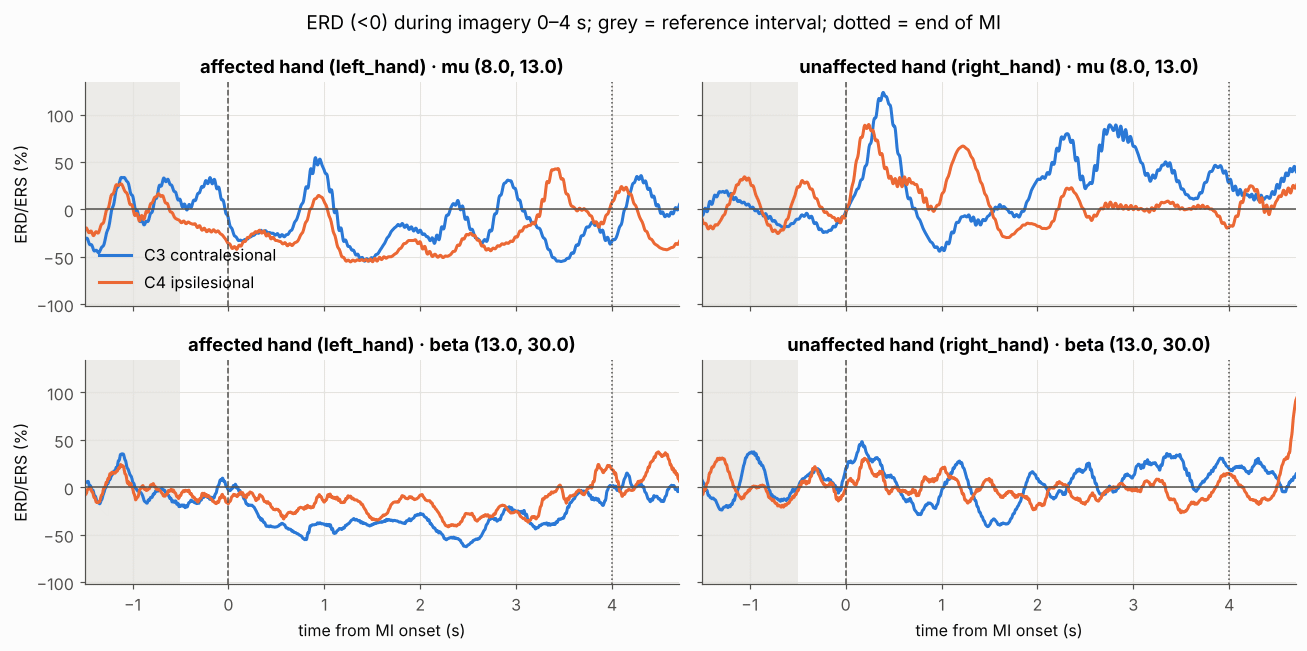

In [17]:
Xcar = S.car(ep.get_data(picks="eeg")); names = [c for c in ep.ch_names if c not in C.EOG_CHANNELS]
times = ep.times; cl, il = names.index(CTRL), names.index(IPSI)
fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for col, (hand, lab) in enumerate([("affected", AFF), ("unaffected", UNAFF)]):
    sel = keep & (ep.events[:, 2] == ep.event_id[lab])
    for row, b in enumerate(["mu", "beta"]):
        e = F.erd_timecourse(Xcar[sel], 250, times, C.BANDS[b], C.ERD_REF_WIN)
        a = axs[row, col]
        a.plot(times, e[cl], color=V.CL_COLOR, label=f"{CTRL} contralesional")
        a.plot(times, e[il], color=V.IL_COLOR, label=f"{IPSI} ipsilesional")
        a.axhline(0, color=V.INK2, lw=1); a.axvspan(*C.ERD_REF_WIN, color=V.GRID, alpha=.7, lw=0)
        a.axvline(0, color=V.INK2, ls="--", lw=1); a.axvline(4, color=V.INK2, ls=":", lw=1)
        a.set_title(f"{hand} hand ({lab}) · {b} {C.BANDS[b]}"); a.set_xlim(-1.5, 4.7)  # hide epoch-edge filter artefacts
axs[0, 0].legend(loc="lower left"); axs[1, 0].set_xlabel("time from MI onset (s)"); axs[1, 1].set_xlabel("time from MI onset (s)")
for a in axs[:, 0]: a.set_ylabel("ERD/ERS (%)")
fig.suptitle("ERD (<0) during imagery 0–4 s; grey = reference interval; dotted = end of MI"); plt.tight_layout(); plt.show()

**Observation (patient 02).** During **affected-hand** imagery (left column), **β power over C3, the healthy hemisphere, drops by ~30–50%** throughout the 4 s of imagery, and more than over C4 (the lesioned side). This *looks like* the ipsilateral signal IpsiHand relies on. Imagery of the **unaffected** hand gives no comparable ERD here. But single-patient curves are noisy (≈ 20 trials), and notebook 02 (Q2) shows that across 47 patients the lateralisation follows the *imagined hand* for both hands, so it is not clean evidence of lesion-driven recruitment.

### 10.1 Time–frequency map (Morlet wavelets)
A wavelet transform gives power at every (time, frequency) point. A Morlet wavelet is a sine wave under a Gaussian window, with `n_cycles = f/2` so the time window shrinks as frequency rises: good time resolution at high frequencies, good frequency resolution at low frequencies (the time–frequency trade-off). Shown as log-ratio vs the reference (dB).

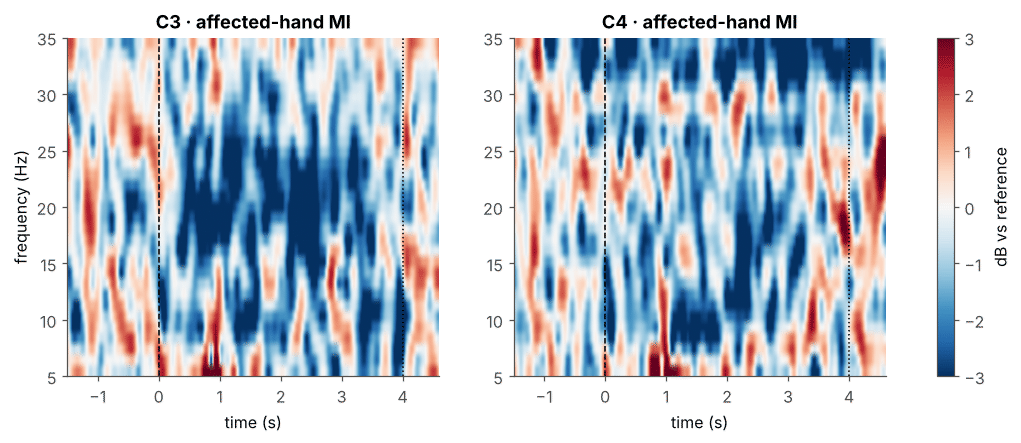

In [18]:
ep_car = ep.copy().pick("eeg").set_eeg_reference("average")
freqs = np.arange(5, 36, 1.0)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sel = np.flatnonzero(keep & (ep.events[:, 2] == ep.event_id[AFF]))
tfr = ep_car[sel].compute_tfr("morlet", freqs=freqs, n_cycles=freqs / 2, picks=[CTRL, IPSI], return_itc=False, average=True)
tfr.apply_baseline(C.ERD_REF_WIN, mode="logratio")
for a, ch in zip(axs, [CTRL, IPSI]):
    d = 10 * tfr.copy().pick([ch]).crop(-1.5, 4.6).data[0]
    im = a.imshow(d, aspect="auto", origin="lower", extent=[-1.5, 4.6, freqs[0], freqs[-1]], cmap=V.DIVERGING, vmin=-3, vmax=3)
    a.axvline(0, color="k", ls="--", lw=1); a.axvline(4, color="k", ls=":", lw=1); a.set_title(f"{ch} · affected-hand MI"); a.set_xlabel("time (s)"); a.grid(False)
axs[0].set_ylabel("frequency (Hz)"); plt.colorbar(im, ax=axs, label="dB vs reference"); plt.show()

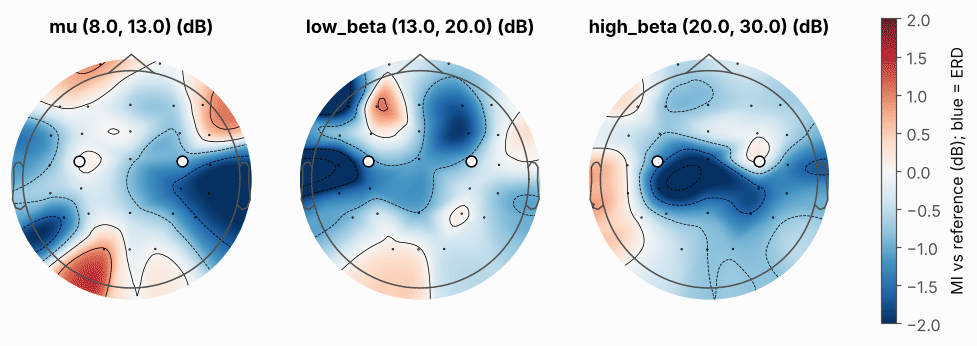

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
sel_aff = keep & (ep.events[:, 2] == ep.event_id[AFF])
for a, b in zip(axs, ["mu", "low_beta", "high_beta"]):
    e = F.erd_per_trial(Xcar[sel_aff], 250, times, C.BANDS[b], C.MI_WIN, C.ERD_REF_WIN)
    im = V.topomap(dict(zip(names, np.median(e, 0))), a, vlim=(-2, 2), title=f"{b} {C.BANDS[b]} (dB)", mask_chs=[CTRL, IPSI])
plt.colorbar(im, ax=axs, label="MI vs reference (dB); blue = ERD"); plt.show()

## 11 · Features: the r² map (how IpsiHand screens a patient)
For each channel × 1-Hz bin, compute log-power in **MI** windows vs **rest** windows and the **signed r²** (squared point-biserial correlation). It is the fraction of the feature's variance explained by the label; the sign is negative for ERD. BCI2000 and the IpsiHand study pick the control feature as the healthy-hemisphere electrode + frequency with the strongest r².

**Welch vs AR (maximum entropy) on a 500 ms window.** At 250 Hz a 0.5 s window has 125 samples. An FFT then gives 2 Hz bins and very high variance. An **AR model** (order 16, Burg's method) fits a 16-coefficient linear predictor and reads the spectrum off its transfer function, giving smooth, sharp peaks from few samples. That's why online BCIs (BCI2000, IpsiHand) use it.

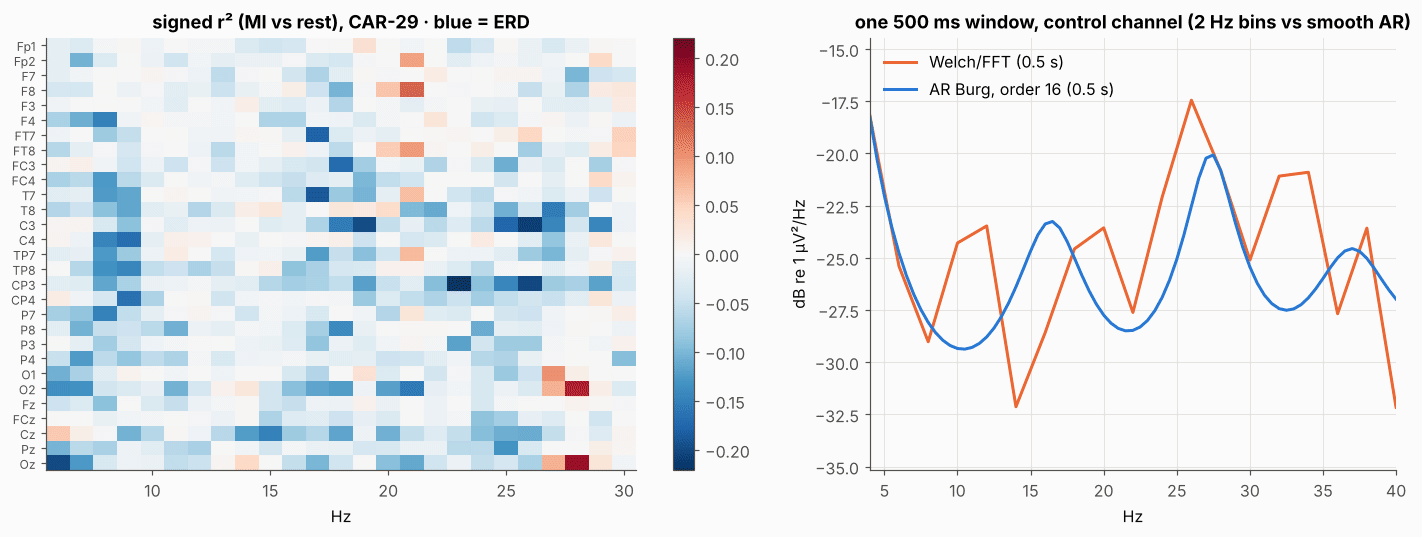

In [20]:
Xc = S.car(ds.X)
fr, Pw = F.welch_psd(Xc, 250, nperseg=250)
m = (fr >= 6) & (fr <= 30)
r2 = F.signed_r2(np.log10(Pw[ds.y == 1][..., m]), np.log10(Pw[ds.y == 0][..., m]))
order = [n for pair in C.HOMOLOGOUS_PAIRS for n in pair if n in names] + [n for n in C.MIDLINE if n in names]
idx = [names.index(n) for n in order]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1.4, 1]))
lim = np.abs(r2).max()
im = ax[0].imshow(r2[idx], aspect="auto", cmap=V.DIVERGING, vmin=-lim, vmax=lim, extent=[fr[m][0]-.5, fr[m][-1]+.5, len(idx)-.5, -.5])
ax[0].set_yticks(range(len(idx))); ax[0].set_yticklabels(order, fontsize=8); ax[0].set_xlabel("Hz"); ax[0].grid(False)
ax[0].set_title("signed r² (MI vs rest), CAR-29 · blue = ERD"); plt.colorbar(im, ax=ax[0])
x = D.control_signal(ds, "car6"); seg = x[:, :125]
f_ar, p_ar = F.ar_psd(seg, 250, order=16, freqs=np.arange(4, 41, 0.5)); f_w, p_w = signal.welch(seg, fs=250, nperseg=125)
ax[1].plot(f_w, 10*np.log10(p_w[0]*1e12), color=V.SERIES[1], label="Welch/FFT (0.5 s)")
ax[1].plot(f_ar, 10*np.log10(p_ar[0]*1e12), color=V.SERIES[0], label="AR Burg, order 16 (0.5 s)")
sel_w = (f_w >= 4) & (f_w <= 40); yv = np.r_[10*np.log10(p_w[0][sel_w]*1e12), 10*np.log10(p_ar[0]*1e12)]
ax[1].set_ylim(yv.min() - 3, yv.max() + 3)
ax[1].set_xlim(4, 40); ax[1].set_xlabel("Hz"); ax[1].set_ylabel("dB re 1 µV²/Hz"); ax[1].legend(); ax[1].set_title("one 500 ms window, control channel (2 Hz bins vs smooth AR)")
plt.tight_layout(); plt.show()

## 12 · Decoding intent (MI vs rest) with leakage-safe cross-validation
- **Task:** affected-hand imagery window (0.5–2.0 s) vs instruction-period "rest" (−1.5–0 s), 1.5 s each. Caveat: the cue is on screen during "rest", so it is attentive rest. A real device would also be calibrated on true rest.
- **Metric:** **ROC AUC** (threshold-free; 0.5 = chance). With ~20 trials per class, chance can easily reach ~0.65, so notebook 02 uses **permutation tests**.
- **CV:** `StratifiedGroupKFold`, 5 folds × 5 repeats. Both windows of a trial stay in the same fold (group = trial). Every data-driven choice (the frequency bin, CSP filters) is fitted **inside the training fold only**. Selecting the best bin on all the data and then cross-validating is the most common leakage bug in BCI papers.
- **Decoders:** (a) *IpsiHand-like*: one channel, one patient-specific 1-Hz bin restricted to ERD (power decrease), and a 1-feature LDA; (b) the same with fixed μ+β band power; (c) all-29-channel CSP+LDA and Riemannian tangent space as upper bounds.

**LDA** (linear discriminant analysis) projects the features onto the direction that best separates the classes, assuming Gaussian classes with a shared covariance. With few trials, **shrinkage** (Ledoit–Wolf) regularises that covariance. **CSP** (common spatial patterns) learns spatial filters that maximise variance for one class while minimising it for the other; log-variance of the filtered signals = band power. **Tangent space** maps each trial's covariance matrix (a point on a curved Riemannian manifold) onto a flat space where linear classifiers work. It is currently the most robust approach for small datasets.

In [21]:
rows = []
for der in ["raw", "bip_cp", "bip_fc", "lap4", "car6", "car8", "car29"]:
    for site in ["CL:C", "IL:C"]:
        x = D.control_signal(ds, der, site)
        rows.append(dict(derivation=der, site=site, auc=D.cv_auc(D.best_bin_decoder(D.spectrum_1hz(x, 250), ds.y), None, ds.y, ds.groups)))
Xb = D.bandpass(ds.X, 250)
rows.append(dict(derivation="CSP-29", site="multi", auc=D.cv_auc(D.csp_decoder(Xb, ds.y), None, ds.y, ds.groups)))
rows.append(dict(derivation="TangentSpace-29", site="multi", auc=D.cv_auc(D.tangent_space_decoder(Xb, ds.y), None, ds.y, ds.groups)))
res = pd.DataFrame(rows); res.pivot_table(index="derivation", columns="site", values="auc").round(3)

site,CL:C,IL:C,multi
derivation,,,
CSP-29,NaN,NaN,0.520
TangentSpace-29,NaN,NaN,0.725
bip_cp,0.660,0.532,NaN
bip_fc,0.550,0.470,NaN
car29,0.608,0.668,NaN
car6,0.695,0.532,NaN
car8,0.700,0.532,NaN
lap4,0.638,0.792,NaN
raw,0.708,0.515,NaN


## 13 · Pseudo-online: what the device would actually do
Everything from here on is **causal**:
1. causal Butterworth 1–40 Hz (state reset at each segment), then decimate to 250 Hz,
2. CAR over the 6 montage electrodes → control channel,
3. AR power on a **500 ms window every 125 ms**,
4. calibration on the **first half** of affected-hand trials: pick the bin with the strongest ERD (most negative r²), and store the rest mean/SD,
5. test on the **second half**: z-score each new window against rest and integrate into a hand aperture Y ∈ [0, 100]% (the Bundy 2017 control law):
   `Y(t) = Y(t−1) + gain · (sign · z − bias)`.

`bias` keeps the hand closed at rest; `gain` sets the speed. In the clinic both are tuned per patient: the trade-off is responsiveness vs false openings.

calibrated control frequency = 18 Hz, r² = -0.138; window-level test AUC = 0.577


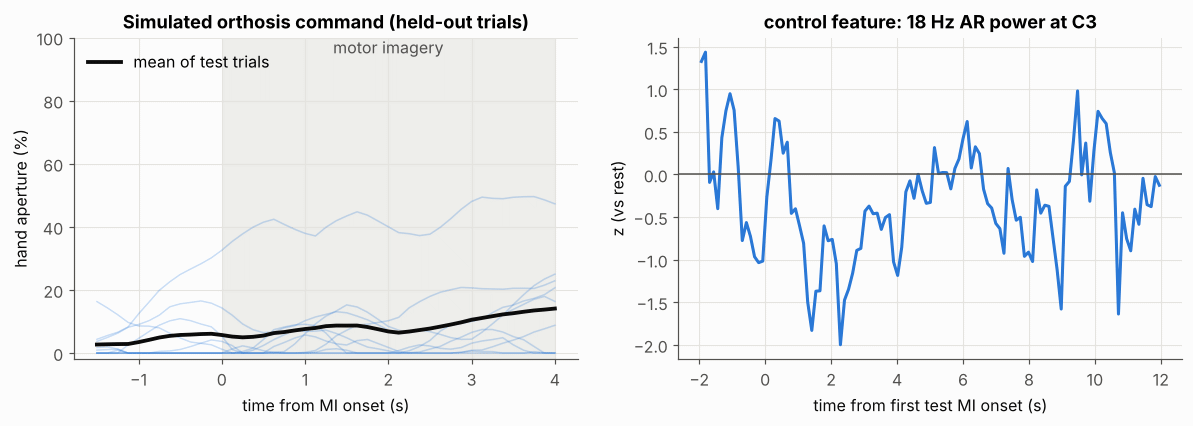

In [22]:
res_on = O.run_subject(io.load_raw(SUBJECT), hemi, AFF)
cal = res_on["cal"]
print(f"calibrated control frequency = {cal.freq:.0f} Hz, r² = {cal.r2:.3f}; window-level test AUC = {res_on['auc_test_windows']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
lags, tr = res_on["lags"], res_on["traces"]
for y in tr: ax[0].plot(lags, y, color=V.SERIES[0], alpha=.25, lw=1)
ax[0].plot(lags, tr.mean(0), color=V.INK, lw=2.5, label="mean of test trials")
ax[0].axvspan(0, 4, color=V.GRID, alpha=.6, lw=0); ax[0].text(2, 95, "motor imagery", ha="center", color=V.INK2)
ax[0].set_ylim(-2, 100); ax[0].set_xlabel("time from MI onset (s)"); ax[0].set_ylabel("hand aperture (%)"); ax[0].legend(loc="upper left"); ax[0].set_title("Simulated orthosis command (held-out trials)")
t, fz = res_on["t"], res_on["feat"]
o = res_on["test_onsets"][0]; m = (t > o - 2) & (t < o + 12)
ax[1].plot(t[m] - o, (fz[m] - cal.mu_rest) / cal.sd_rest, color=V.SERIES[0])
ax[1].axhline(0, color=V.INK2, lw=1); ax[1].set_xlabel("time from first test MI onset (s)"); ax[1].set_ylabel("z (vs rest)"); ax[1].set_title(f"control feature: {cal.freq:.0f} Hz AR power at {CTRL}")
plt.show()

**Interpretation.** The control feature does dip below rest during imagery, but after calibrating on only 10 trials the simulated hand opens only partially (mean aperture rises from ~5% to ~15%). This is realistic for a first session with an *acute* patient doing *imagery*. IpsiHand patients trained for weeks with *attempted* movement and daily re-calibration (90 s rest + 30/30 trials). Levers to improve: more calibration data, per-patient tuning of gain and bias, adaptive (rolling) normalisation, and a montage whose reference does not cancel the ERD (notebook 02).

## 14 · Summary: the pipeline in one table
| # | Step | Parameter | Why | Alternative / trade-off |
|---|---|---|---|---|
| 1 | DC removal | per-segment mean | DC-coupled amp, offsets of mV ≫ µV EEG | causal: subtract the first sample or a running mean |
| 2 | High-pass | 1 Hz FIR, zero-phase | drift and sweat; we study oscillations | 0.1 Hz if MRCPs are used; causal IIR online |
| 3 | Notch | 50 (60 in US) Hz + harmonics | mains; also a contact-quality metric | redundant when LP ≤ 40 Hz with a steep FIR |
| 4 | Low-pass | 40 Hz | μ/β < 30 Hz; > 40 Hz is mostly EMG; anti-aliasing | keep up to 100 Hz to *detect* EMG / real movement |
| 5 | Channel QC | robust z, neighbour correlation, 1/f slope | automatic, patient-independent | impedance check at set-up (hardware) |
| 6 | Downsample | 500 → 250 Hz (polyphase) | Nyquist 125 ≫ 40; halves compute | 125 Hz is still fine for μ/β |
| 7 | EOG | linear regression | works with few channels, online-compatible | ICA (dense caps, offline) |
| 8 | Trial rejection | 150 µV p-p on decoder channels only | keep trials whose motor channels are clean | adaptive thresholds; Artifact Subspace Reconstruction (ASR) |
| 9 | Reference | CAR-6 (device-like) | removes common-mode noise | Laplacian, bipolar → fewer electrodes (notebook 02) |
| 10 | Epochs | MI 0.5–2.0 s vs rest −1.5–0 s | strongest ERD; skip visual evoked response | longer windows = more SNR, more latency |
| 11 | Features | log power, 1-Hz bins 6–30 Hz | ERD lives in μ/β; log → Gaussian-like | band power; CSP; covariance (Riemann) |
| 12 | Decoder | ERD-constrained best bin + LDA | interpretable, few parameters, IpsiHand-like | tangent space with more channels |
| 13 | Online | causal IIR, 500 ms AR every 125 ms | latency ≈ 0.3–0.5 s | shorter windows → noisier |